# De Bortoli et al. Diffusion Schrödinger Bridge in JAX

This notebook implements the **Diffusion Schrödinger Bridge (DSB)** recursion from:

> V. De Bortoli, J. Thornton, J. Heng, A. Doucet,  
> *Diffusion Schrödinger Bridge with Applications to Score-Based Generative Modeling*, NeurIPS 2021.

The implementation follows the paper's **alternating IPF recursion** and, for the 2-D setting, uses the **drift-matching formulation** from Appendix E.2.2 together with the small fully-connected architecture described in Appendix J.1.

For arbitrary source and target point clouds, we use a Brownian reference diffusion:
$dX_t = \sqrt{2}\,dW_t.$

At IPF iteration \(n\),

$X_{k+1} = X_k + \gamma f_k^n(X_k) + \sqrt{2\gamma}Z_{k+1},$

and the reverse process is

$X_k = X_{k+1} + \gamma b_{k+1}^n(X_{k+1}) + \sqrt{2\gamma}\widetilde Z_{k+1}.$

The learned drift regressions are

$b_{k+1}^{n}
=
\arg\min_b
\mathbb E\left[
\left\|
b(X_{k+1})
-
\frac{F_k^n(X_k)-F_k^n(X_{k+1})}{\gamma}
\right\|^2
\right],$

$f_k^{n+1}
=
\arg\min_f
\mathbb E\left[
\left\|
f(X_k)
-
\frac{B_{k+1}^n(X_{k+1})-B_{k+1}^n(X_k)}{\gamma}
\right\|^2
\right],$

with
$F_k^n(x)=x+\gamma f_k^n(x),\qquad
B_{k+1}^n(x)=x+\gamma b_{k+1}^n(x).$

This is the key difference from a naive local-velocity regression implementation.

In [1]:
# If needed:
# %pip install -q "jax[cuda12]" flax optax matplotlib

import math
from functools import partial

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from flax import linen as nn
from flax.training import train_state
import optax

print("JAX:", jax.__version__)
print("Devices:", jax.devices())

JAX: 0.11.1
Devices: [CudaDevice(id=0), CudaDevice(id=1)]


## 1. Configuration

The paper's 2-D experiments use:

- Adam, learning rate \(10^{-4}\)
- batch size 512
- \(\gamma_k=10^{-2}\)
- cache size \(10^4\)
- cache refresh every \(10^3\) optimization steps
- \(10^4\) optimization steps per DSB half-step

For 2-D dataset interpolation, the paper uses 50 diffusion steps.

Set `PAPER_SETTINGS=True` for those expensive settings. The default below is a smaller development configuration.

In [29]:
SEED = 0
key = jax.random.PRNGKey(SEED)

PAPER_SETTINGS = True

N_DATA = 10_000
DIM = 2

N_STEPS = 50
GAMMA = 1e-2
T = N_STEPS * GAMMA
NOISE_STD = jnp.sqrt(2.0 * GAMMA)

BATCH_SIZE = 512
LR = 1e-4
N_IPF = 100

if PAPER_SETTINGS:
    CACHE_SIZE = 10_000
    REFRESH_EVERY = 1_000
    TRAIN_STEPS_PER_HALF = 10_000
else:
    CACHE_SIZE = 4_096
    REFRESH_EVERY = 250
    TRAIN_STEPS_PER_HALF = 1_000

print({
    "N_STEPS": N_STEPS,
    "gamma": GAMMA,
    "T": T,
    "N_IPF": N_IPF,
    "train_steps_per_half": TRAIN_STEPS_PER_HALF,
    "cache_size": CACHE_SIZE,
})

{'N_STEPS': 50, 'gamma': 0.01, 'T': 0.5, 'N_IPF': 100, 'train_steps_per_half': 10000, 'cache_size': 10000}


## 2. Two toy endpoint distributions

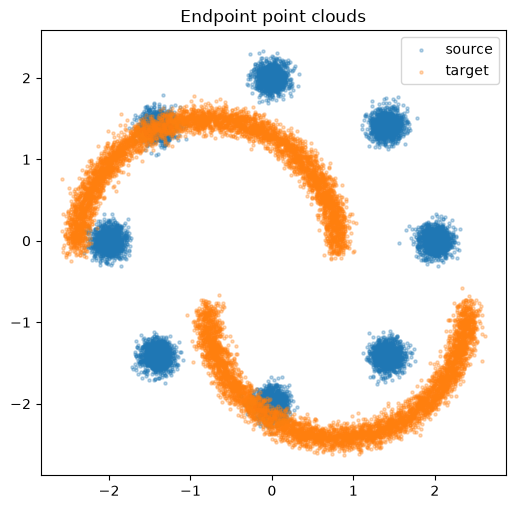

In [30]:
def sample_ring(key, n, radius=2.0, noise=0.10, n_modes=8):
    k1, k2 = jax.random.split(key)
    idx = jax.random.randint(k1, (n,), 0, n_modes)
    ang = 2 * jnp.pi * idx / n_modes
    centers = radius * jnp.stack([jnp.cos(ang), jnp.sin(ang)], -1)
    return centers + noise * jax.random.normal(k2, (n, 2))


def sample_two_moons(key, n, noise=0.08):
    k1, k2, k3 = jax.random.split(key, 3)
    side = jax.random.bernoulli(k1, 0.5, (n,))
    ang = jax.random.uniform(k2, (n,), minval=0.0, maxval=jnp.pi)

    a = jnp.stack([jnp.cos(ang), jnp.sin(ang)], -1)
    b = jnp.stack([1.0 - jnp.cos(ang), -jnp.sin(ang) - 0.45], -1)
    x = jnp.where(side[:, None], a, b)

    x = 1.6 * x - jnp.array([0.8, 0.1])
    return x + noise * jax.random.normal(k3, (n, 2))


key, ks, kt = jax.random.split(key, 3)
source_data = sample_ring(ks, N_DATA)
target_data = sample_two_moons(kt, N_DATA)

fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(np.asarray(source_data[:,0]), np.asarray(source_data[:,1]), s=5, alpha=.3, label="source")
ax.scatter(np.asarray(target_data[:,0]), np.asarray(target_data[:,1]), s=5, alpha=.3, label="target")
ax.set_aspect("equal")
ax.legend()
ax.set_title("Endpoint point clouds")
plt.show()

## 3. Network used for 2-D DSB

The paper's 2-D architecture has:

- state branch: \(2	o16	o32\)
- time branch: \(1	o16	o32\), with sinusoidal positional encoding
- concatenate to 64 dimensions
- joint MLP: \(64	o128	o128	o2\)

The network predicts the **drift**, not the transition mean.

In [31]:
class DSBDrift2D(nn.Module):
    @nn.compact
    def __call__(self, x, k):
        # x: (B, 2), k: (B, 1) in integer step coordinates
        hx = nn.swish(nn.Dense(16)(x))
        hx = nn.swish(nn.Dense(32)(hx))

        # 1 -> 16 -> 32, using sine as positional nonlinearity
        ht = nn.Dense(16)(k)
        ht = jnp.sin(ht)
        ht = nn.swish(nn.Dense(32)(ht))

        h = jnp.concatenate([hx, ht], axis=-1)
        h = nn.swish(nn.Dense(128)(h))
        h = nn.swish(nn.Dense(128)(h))
        return nn.Dense(2)(h)


def make_state(key, zero_output=False):
    model = DSBDrift2D()
    params = model.init(
        key,
        jnp.zeros((1, 2)),
        jnp.zeros((1, 1)),
    )["params"]

    if zero_output:
        # Force the initial learned drift to zero for a Brownian reference.
        # This leaves hidden features intact but makes the final map exactly zero.
        p = dict(params)
        last = list(p.keys())[-1]
        p[last] = {
            "kernel": jnp.zeros_like(p[last]["kernel"]),
            "bias": jnp.zeros_like(p[last]["bias"]),
        }
        params = p

    tx = optax.adam(LR, b1=0.9)
    state = train_state.TrainState.create(
        apply_fn=model.apply,
        params=params,
        tx=tx,
    )
    return model, state


key, kf, kb = jax.random.split(key, 3)
forward_model, forward_state = make_state(kf, zero_output=True)   # f^0 = 0 Brownian
backward_model, backward_state = make_state(kb, zero_output=False)

def nparams(params):
    return sum(x.size for x in jax.tree_util.tree_leaves(params))

print("forward params:", nparams(forward_state.params))
print("backward params:", nparams(backward_state.params))

forward params: 26258
backward params: 26258


## 4. Forward and backward samplers

The discrete kernels are exactly of the DSB form

$p^n_{k+1|k}
=
\mathcal N(F_k^n(x_k),2\gamma I),
\qquad
q^n_{k|k+1}
=
\mathcal N(B_{k+1}^n(x_{k+1}),2\gamma I).$

In [32]:
def step_feature(k, batch):
    # Normalize only for numerical conditioning.
    return jnp.full((batch, 1), k / N_STEPS, dtype=jnp.float32)


@partial(jax.jit, static_argnums=(0,))
def drift_eval(apply_fn, params, x, k):
    kk = step_feature(k, x.shape[0])
    return apply_fn({"params": params}, x, kk)


@partial(jax.jit, static_argnums=(0,))
def simulate_forward(apply_fn, params, x0, key):
    def body(carry, k):
        x, key = carry
        key, sub = jax.random.split(key)
        f = drift_eval(apply_fn, params, x, k)
        x_next = x + GAMMA * f + NOISE_STD * jax.random.normal(sub, x.shape)
        return (x_next, key), x_next

    (_, _), xs = jax.lax.scan(body, (x0, key), jnp.arange(N_STEPS))
    return jnp.concatenate([x0[None], xs], axis=0)


@partial(jax.jit, static_argnums=(0,))
def simulate_backward(apply_fn, params, xN, key):
    # Returned in physical-time order: [x0, ..., xN]
    def body(carry, r):
        x_next, key = carry
        key, sub = jax.random.split(key)
        k = N_STEPS - 1 - r

        b = drift_eval(apply_fn, params, x_next, k + 1)
        x = x_next + GAMMA * b + NOISE_STD * jax.random.normal(sub, x_next.shape)
        return (x, key), x

    (_, _), xs_rev = jax.lax.scan(body, (xN, key), jnp.arange(N_STEPS))
    xs = jnp.flip(xs_rev, axis=0)
    return jnp.concatenate([xs, xN[None]], axis=0)

For trajectories generated by the forward process \(p^n\), the backward drift is trained with the target
$\mathrm{target}_b
\frac{F_k^n(X_k)-F_k^n(X_{k+1})}{\gamma}.$
Similarly, for trajectories generated by the backward process \(q^n\), the forward drift is trained with the target
$\mathrm{target}_f
\frac{B_{k+1}^n(X_{k+1})-B_{k+1}^n(X_k)}{\gamma}.$
Here,
$F_k^n(x)=x+\gamma f_k^n(x)$
and
$B_{k+1}^n(x)=x+\gamma b_{k+1}^n(x).$
The important point is that the regression targets are constructed from the current transition maps evaluated at both endpoints of each sampled transition. They are therefore not the naive finite-difference velocity
$\frac{X_{k+1}-X_k}{\gamma}.$

In [33]:
@partial(jax.jit, static_argnums=(0,))
def backward_target(forward_apply, forward_params, xk, xkp1, k):
    fk_xk = drift_eval(forward_apply, forward_params, xk, k)
    fk_xkp1 = drift_eval(forward_apply, forward_params, xkp1, k)

    F_xk = xk + GAMMA * fk_xk
    F_xkp1 = xkp1 + GAMMA * fk_xkp1
    return (F_xk - F_xkp1) / GAMMA


@partial(jax.jit, static_argnums=(0,))
def forward_target(backward_apply, backward_params, xk, xkp1, k):
    bk1_xkp1 = drift_eval(backward_apply, backward_params, xkp1, k + 1)
    bk1_xk = drift_eval(backward_apply, backward_params, xk, k + 1)

    B_xkp1 = xkp1 + GAMMA * bk1_xkp1
    B_xk = xk + GAMMA * bk1_xk
    return (B_xkp1 - B_xk) / GAMMA


@jax.jit
def regression_step(state, x, k, target):
    def loss_fn(params):
        pred = state.apply_fn({"params": params}, x, k)
        return jnp.mean(jnp.sum((pred - target) ** 2, axis=-1))

    loss, grads = jax.value_and_grad(loss_fn)(state.params)
    state = state.apply_gradients(grads=grads)
    return state, loss

## 6. Trajectory cache

The original 2-D implementation uses cached trajectories and periodically refreshes them.

We store full trajectories with shape

$(N+1,\;M,\;2).$

A minibatch randomly selects both a trajectory index and a time index.

In [34]:
def draw_empirical(key, data, n):
    idx = jax.random.randint(key, (n,), 0, data.shape[0])
    return data[idx]


def make_forward_cache(key, state):
    key, k0, kp = jax.random.split(key, 3)
    x0 = draw_empirical(k0, source_data, CACHE_SIZE)
    traj = simulate_forward(state.apply_fn, state.params, x0, kp)
    return traj, key


def make_backward_cache(key, state):
    key, kN, kp = jax.random.split(key, 3)
    xN = draw_empirical(kN, target_data, CACHE_SIZE)
    traj = simulate_backward(state.apply_fn, state.params, xN, kp)
    return traj, key


@jax.jit
def sample_pairs(key, traj, batch_size=BATCH_SIZE):
    k1, k2 = jax.random.split(key)
    ks = jax.random.randint(k1, (batch_size,), 0, N_STEPS)
    js = jax.random.randint(k2, (batch_size,), 0, traj.shape[1])

    xk = traj[ks, js]
    xkp1 = traj[ks + 1, js]
    return ks, xk, xkp1

## 7. Train \(b^n\) from forward trajectories

In [35]:
def train_backward_half(key, forward_state, backward_state):
    cache, key = make_forward_cache(key, forward_state)
    losses = []

    for it in range(TRAIN_STEPS_PER_HALF):
        if it > 0 and it % REFRESH_EVERY == 0:
            cache, key = make_forward_cache(key, forward_state)

        key, kb = jax.random.split(key)
        ks, xk, xkp1 = sample_pairs(kb, cache)

        # Vectorized because each example may use a different k.
        target = jax.vmap(
            lambda a, b, kk: backward_target(
                forward_state.apply_fn,
                forward_state.params,
                a[None],
                b[None],
                kk,
            )[0]
        )(xk, xkp1, ks)

        kin = (ks + 1).astype(jnp.float32)[:, None] / N_STEPS
        backward_state, loss = regression_step(
            backward_state,
            xkp1,
            kin,
            jax.lax.stop_gradient(target),
        )
        losses.append(float(loss))

    return backward_state, float(np.mean(losses)), key

## 8. Train \(f^{n+1}\) from backward trajectories

In [36]:
def train_forward_half(key, backward_state, forward_state):
    cache, key = make_backward_cache(key, backward_state)
    losses = []

    for it in range(TRAIN_STEPS_PER_HALF):
        if it > 0 and it % REFRESH_EVERY == 0:
            cache, key = make_backward_cache(key, backward_state)

        key, kb = jax.random.split(key)
        ks, xk, xkp1 = sample_pairs(kb, cache)

        target = jax.vmap(
            lambda a, b, kk: forward_target(
                backward_state.apply_fn,
                backward_state.params,
                a[None],
                b[None],
                kk,
            )[0]
        )(xk, xkp1, ks)

        kin = ks.astype(jnp.float32)[:, None] / N_STEPS
        forward_state, loss = regression_step(
            forward_state,
            xk,
            kin,
            jax.lax.stop_gradient(target),
        )
        losses.append(float(loss))

    return forward_state, float(np.mean(losses)), key

## 9. Full DSB / IPF recursion

This is the direct analogue of Algorithm 1:

1. simulate \(p^n\) forward from the source;
2. fit \(b^n\);
3. simulate \(q^n\) backward from the target;
4. fit \(f^{n+1}\);
5. repeat.

The networks are warm-started across IPF iterations, matching the refinement strategy suggested in the paper.

In [37]:
history = {
    "backward_loss": [],
    "forward_loss": [],
    "mmd_forward": [],
    "mmd_backward": [],
}


@jax.jit
def rbf_mmd2(x, y, bandwidth=0.5):
    xx = jnp.sum((x[:, None] - x[None, :])**2, axis=-1)
    yy = jnp.sum((y[:, None] - y[None, :])**2, axis=-1)
    xy = jnp.sum((x[:, None] - y[None, :])**2, axis=-1)

    return (
        jnp.mean(jnp.exp(-xx / (2 * bandwidth**2)))
        + jnp.mean(jnp.exp(-yy / (2 * bandwidth**2)))
        - 2 * jnp.mean(jnp.exp(-xy / (2 * bandwidth**2)))
    )


def evaluate(key, forward_state, backward_state, n=1024):
    key, k0, k1, kf, kb = jax.random.split(key, 5)
    x0 = draw_empirical(k0, source_data, n)
    x1 = draw_empirical(k1, target_data, n)

    tf = simulate_forward(forward_state.apply_fn, forward_state.params, x0, kf)
    tb = simulate_backward(backward_state.apply_fn, backward_state.params, x1, kb)

    mf = float(rbf_mmd2(tf[-1], x1))
    mb = float(rbf_mmd2(tb[0], x0))
    return mf, mb, tf, tb, key


for n in range(N_IPF):
    backward_state, b_loss, key = train_backward_half(
        key, forward_state, backward_state
    )

    forward_state, f_loss, key = train_forward_half(
        key, backward_state, forward_state
    )

    mf, mb, _, _, key = evaluate(
        key, forward_state, backward_state, n=512
    )

    history["backward_loss"].append(b_loss)
    history["forward_loss"].append(f_loss)
    history["mmd_forward"].append(mf)
    history["mmd_backward"].append(mb)

    print(
        f"IPF {n+1:02d}/{N_IPF} | "
        f"L_b={b_loss:.5f} | "
        f"L_f={f_loss:.5f} | "
        f"MMD fwd={mf:.5f} | "
        f"MMD bwd={mb:.5f}"
    )

IPF 01/100 | L_b=390.00169 | L_f=378.74478 | MMD fwd=0.01975 | MMD bwd=0.02950
IPF 02/100 | L_b=372.36217 | L_f=369.60084 | MMD fwd=0.01339 | MMD bwd=0.01559
IPF 03/100 | L_b=366.25951 | L_f=365.57874 | MMD fwd=0.00719 | MMD bwd=0.00642
IPF 04/100 | L_b=364.29473 | L_f=362.88705 | MMD fwd=0.00487 | MMD bwd=0.00607
IPF 05/100 | L_b=362.72252 | L_f=361.05378 | MMD fwd=0.00374 | MMD bwd=0.00515
IPF 06/100 | L_b=359.17526 | L_f=360.37831 | MMD fwd=0.00342 | MMD bwd=0.00461
IPF 07/100 | L_b=359.86698 | L_f=359.62853 | MMD fwd=0.00326 | MMD bwd=0.00336
IPF 08/100 | L_b=359.09356 | L_f=359.46574 | MMD fwd=0.00910 | MMD bwd=0.00832
IPF 09/100 | L_b=359.03489 | L_f=357.93771 | MMD fwd=0.00317 | MMD bwd=0.00323
IPF 10/100 | L_b=358.79234 | L_f=358.27516 | MMD fwd=0.00345 | MMD bwd=0.00319
IPF 11/100 | L_b=357.14975 | L_f=358.28519 | MMD fwd=0.00499 | MMD bwd=0.00565
IPF 12/100 | L_b=357.02578 | L_f=358.22231 | MMD fwd=0.00431 | MMD bwd=0.00564
IPF 13/100 | L_b=356.86931 | L_f=358.01491 | MMD fwd

## 10. Training diagnostics

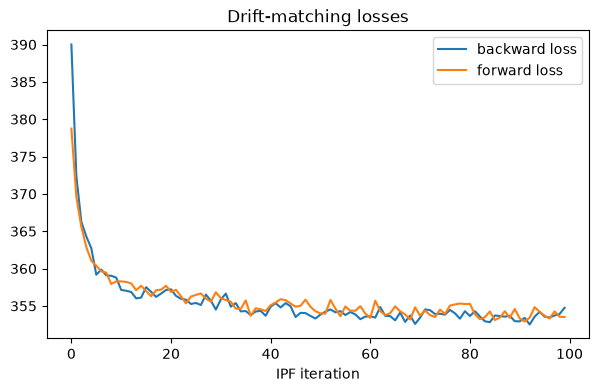

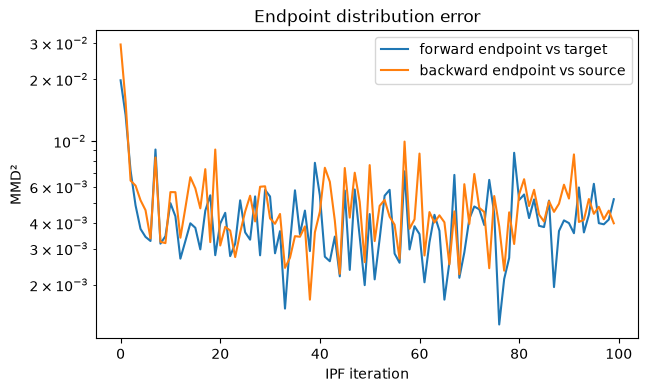

In [42]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history["backward_loss"], label="backward loss")
ax.plot(history["forward_loss"], label="forward loss")
ax.set_xlabel("IPF iteration")
ax.set_title("Drift-matching losses")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.semilogy(history["mmd_forward"], label="forward endpoint vs target")
ax.semilogy(history["mmd_backward"], label="backward endpoint vs source")
ax.set_xlabel("IPF iteration")
ax.set_ylabel("MMD²")
ax.set_title("Endpoint distribution error")
ax.legend()
plt.show()

## 11. Learned bridge marginals

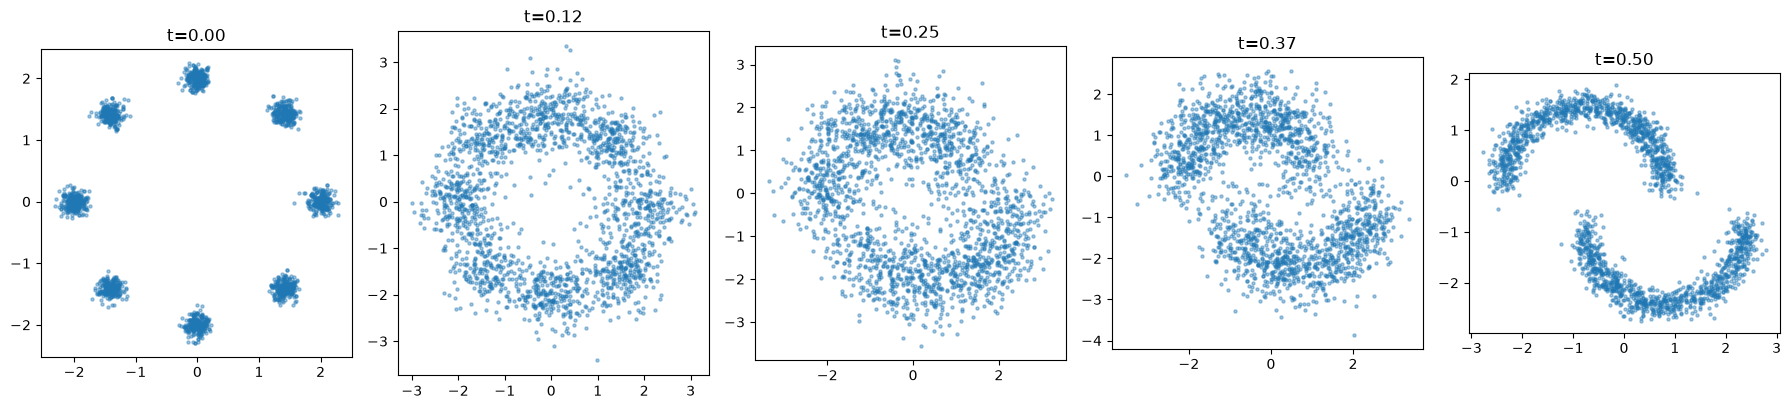

forward MMD²: 0.0022773444652557373
backward MMD²: 0.0028404593467712402


In [43]:
mf, mb, traj_f, traj_b, key = evaluate(
    key, forward_state, backward_state, n=2000
)

snap = [0, N_STEPS//4, N_STEPS//2, 3*N_STEPS//4, N_STEPS]

fig, axes = plt.subplots(1, len(snap), figsize=(18,4))
for ax, k in zip(axes, snap):
    x = np.asarray(traj_f[k])
    ax.scatter(x[:,0], x[:,1], s=5, alpha=.4)
    ax.set_title(f"t={k*GAMMA:.2f}")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("forward MMD²:", mf)
print("backward MMD²:", mb)

## 12. Endpoint comparison

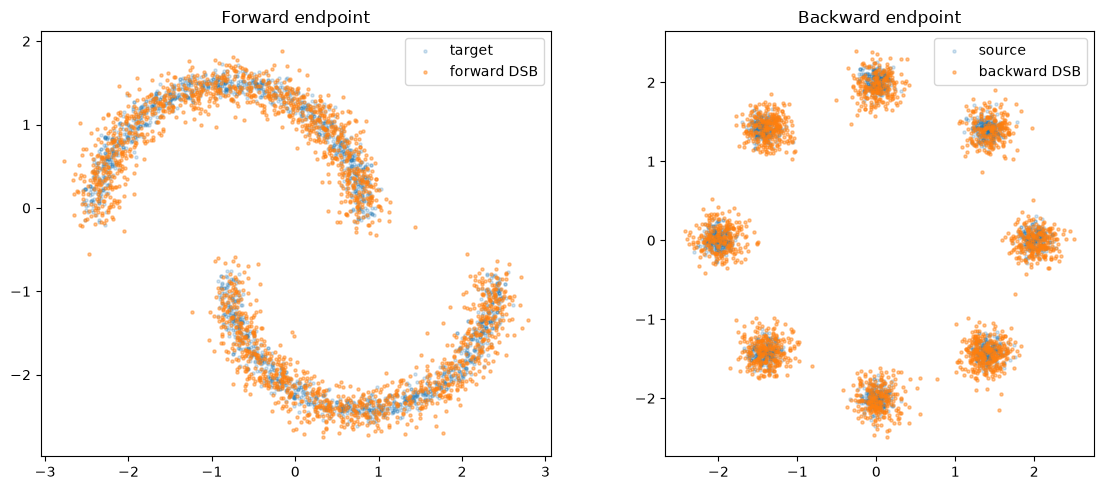

In [44]:
key, k0, k1 = jax.random.split(key, 3)
x0_ref = draw_empirical(k0, source_data, traj_b.shape[1])
x1_ref = draw_empirical(k1, target_data, traj_f.shape[1])

fig, axes = plt.subplots(1,2,figsize=(12,5))

axes[0].scatter(np.asarray(x1_ref[:,0]), np.asarray(x1_ref[:,1]), s=5, alpha=.2, label="target")
axes[0].scatter(np.asarray(traj_f[-1,:,0]), np.asarray(traj_f[-1,:,1]), s=5, alpha=.45, label="forward DSB")
axes[0].set_title("Forward endpoint")
axes[0].set_aspect("equal")
axes[0].legend()

axes[1].scatter(np.asarray(x0_ref[:,0]), np.asarray(x0_ref[:,1]), s=5, alpha=.2, label="source")
axes[1].scatter(np.asarray(traj_b[0,:,0]), np.asarray(traj_b[0,:,1]), s=5, alpha=.45, label="backward DSB")
axes[1].set_title("Backward endpoint")
axes[1].set_aspect("equal")
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Individual stochastic bridge trajectories

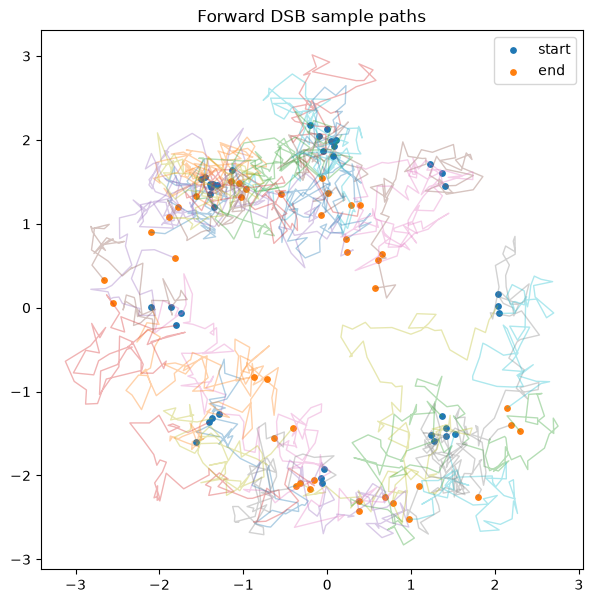

In [45]:
tp = np.asarray(traj_f[:, :40])

fig, ax = plt.subplots(figsize=(7,7))
for i in range(tp.shape[1]):
    ax.plot(tp[:,i,0], tp[:,i,1], alpha=.35, linewidth=1)
ax.scatter(tp[0,:,0], tp[0,:,1], s=15, label="start")
ax.scatter(tp[-1,:,0], tp[-1,:,1], s=15, label="end")
ax.set_aspect("equal")
ax.legend()
ax.set_title("Forward DSB sample paths")
plt.show()

## 14. What is faithful to De Bortoli et al. here?

This notebook implements the essential ingredients of their 2-D DSB method:

- discrete Gaussian kernels with covariance \(2\gamma I\);
- alternating IPF forward/backward simulation;
- drift-matching objectives from Appendix E.2.2;
- \(F_k(x)=x+\gamma f_k(x)\), \(B_{k+1}(x)=x+\gamma b_{k+1}(x)\);
- the 2-D MLP dimensions described in Appendix J.1;
- Adam with learning rate \(10^{-4}\);
- \(\gamma=10^{-2}\);
- batch size 512;
- trajectory caching and periodic refresh;
- warm-starting/refinement across DSB iterations.

For their exact published 2-D training budget, set `PAPER_SETTINGS=True`.

The main deliberate adaptation is that the target endpoint here is another arbitrary empirical point cloud rather than a Gaussian prior. DSB itself allows this; the paper also demonstrates dataset interpolation between arbitrary distributions.